In [ ]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.optimize import curve_fit
import seaborn as sns

# -----------------------------------------------------------------------------
# 1. Load Data & Prepare Variables
# -----------------------------------------------------------------------------
data_path = Path('../data/synthetic_bucket_data_b8.csv')
df = pd.read_csv(data_path)

# H = Entropy (bits), y_true = True Expected Remaining Cost (C_true - 1)
H = df['bucket_entropy'].values
y_true = df['true_expected_cost'].values - 1.0

# Sort for continuous plotting
sort_idx = np.argsort(H)
H_sorted = H[sort_idx]
y_sorted = y_true[sort_idx]

In [ ]:
import pandas as pd
import numpy as np
import ast
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Assuming df is already loaded from your initial cell
# df = pd.read_csv('your_data.csv')

def extract_p1(details_str):
    """Parses the dictionary string and returns the highest probability (p1)."""
    try:
        details = ast.literal_eval(details_str)
        if details:
            return max(details.values())
        return 0.0
    except (ValueError, SyntaxError):
        return 0.0

# Apply parsing
df['p1'] = df['bucket_details'].apply(extract_p1)
df['formula_2_minus_p1'] = 2.0 - df['p1']

# Filter for H < 0.5
df_low_h = df[df['bucket_entropy'] < 0.5].copy()

# Calculate metrics
if len(df_low_h) > 0:
    mae_low = mean_absolute_error(df_low_h['true_expected_cost'], df_low_h['formula_2_minus_p1'])
    rmse_low = np.sqrt(mean_squared_error(df_low_h['true_expected_cost'], df_low_h['formula_2_minus_p1']))
    r2_low = r2_score(df_low_h['true_expected_cost'], df_low_h['formula_2_minus_p1'])
    
    print(f"=== H < 0.5 FORMULA VALIDATION (N={len(df_low_h)}) ===")
    print(f"Formula: E = 2 - p1")
    print(f"MAE:  {mae_low:.5f}")
    print(f"RMSE: {rmse_low:.5f}")
    print(f"R²:   {r2_low:.5f}")
else:
    print("No samples with H < 0.5 found in the dataset.")

=== H < 0.5 FORMULA VALIDATION (N=25) ===
Formula: E = 2 - p1
MAE:  0.00279
RMSE: 0.00474
R²:   0.96620


In [ ]:
from scipy.optimize import curve_fit

# Filter for H >= 0.5
df_high = df[df['bucket_entropy'] >= 0.5].copy()
X = df_high['bucket_entropy'].values
Y = df_high['true_expected_cost'].values

# Define structurally monotonic models
def model_log(x, a, b, c):
    """Logarithmic: Continues to grow, but rate of growth slows down."""
    return a * np.log1p(b * x) + c

def model_exp_asymp(x, a, b, c):
    """Exponential Asymptotic: Approaches a maximum theoretical guess limit 'a'."""
    return a - b * np.exp(-c * x)

def model_power(x, a, b, c):
    """Power Law: Allows fractional powers (like square roots) to curve naturally."""
    return a * (x ** b) + c

models = {
    "Logarithmic": (model_log, [1.0, 1.0, 1.0], {"bounds": ([0, 0, 0], [np.inf, np.inf, 5])}),
    "Exp Asymptotic": (model_exp_asymp, [6.0, 5.0, 0.5], {"bounds": ([1, 0, 0], [10, 10, 5])}),
    "Power Law": (model_power, [1.0, 0.5, 1.0], {"bounds": ([0, 0, 0], [10, 1.0, 5])}) # b <= 1.0 to prevent upward hooking
}

results = {}
print(f"=== H >= 0.5 MODEL EVALUATION (N={len(df_high)}) ===")
print(f"{'Model Name':<18} | {'MAE':<7} | {'RMSE':<7} | {'R²':<7}")
print("-" * 48)

for name, (func, p0, kwargs) in models.items():
    try:
        popt, _ = curve_fit(func, X, Y, p0=p0, maxfev=10000, **kwargs)
        Y_pred = func(X, *popt)
        
        mae = mean_absolute_error(Y, Y_pred)
        rmse = np.sqrt(mean_squared_error(Y, Y_pred))
        r2 = r2_score(Y, Y_pred)
        
        results[name] = {'func': func, 'popt': popt, 'preds': Y_pred}
        print(f"{name:<18} | {mae:.5f} | {rmse:.5f} | {r2:.5f}")
        
    except Exception as e:
        print(f"{name:<18} | FAILED TO FIT: {e}")

=== H >= 0.5 MODEL EVALUATION (N=156) ===
Model Name         | MAE     | RMSE    | R²     
------------------------------------------------
Logarithmic        | 0.07213 | 0.09040 | 0.90917
Exp Asymptotic     | 0.07412 | 0.09204 | 0.90583
Power Law          | 0.07233 | 0.09052 | 0.90891


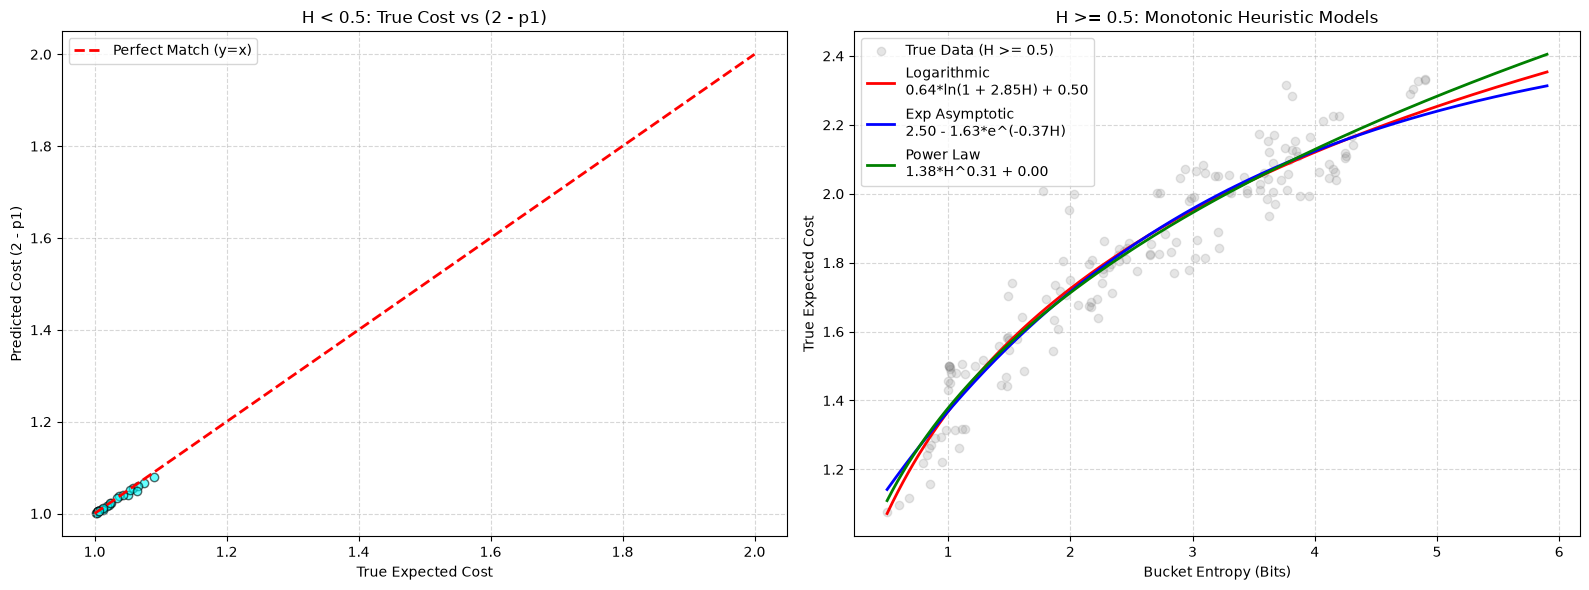

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: H < 0.5 Validation
ax1.scatter(df_low_h['true_expected_cost'], df_low_h['formula_2_minus_p1'], 
            alpha=0.6, edgecolors='k', color='cyan')
ax1.plot([1.0, 2.0], [1.0, 2.0], 'r--', lw=2, label="Perfect Match (y=x)")
ax1.set_title("H < 0.5: True Cost vs (2 - p1)")
ax1.set_xlabel("True Expected Cost")
ax1.set_ylabel("Predicted Cost (2 - p1)")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Plot 2: H >= 0.5 Curve Fits
ax2.scatter(X, Y, alpha=0.2, color='gray', label='True Data (H >= 0.5)')

# Generate smooth lines for the models
x_smooth = np.linspace(X.min(), X.max() + 1.0, 500) # Extend slightly to see extrapolation
colors = ['red', 'blue', 'green']

for (name, data), color in zip(results.items(), colors):
    y_smooth = data['func'](x_smooth, *data['popt'])
    
    # Format the formula for the legend
    p = data['popt']
    if name == "Logarithmic":
        eq = f"{p[0]:.2f}*ln(1 + {p[1]:.2f}H) + {p[2]:.2f}"
    elif name == "Exp Asymptotic":
        eq = f"{p[0]:.2f} - {p[1]:.2f}*e^(-{p[2]:.2f}H)"
    else: # Power
        eq = f"{p[0]:.2f}*H^{p[1]:.2f} + {p[2]:.2f}"
        
    ax2.plot(x_smooth, y_smooth, color=color, lw=2, label=f"{name}\n{eq}")

ax2.set_title("H >= 0.5: Monotonic Heuristic Models")
ax2.set_xlabel("Bucket Entropy (Bits)")
ax2.set_ylabel("True Expected Cost")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

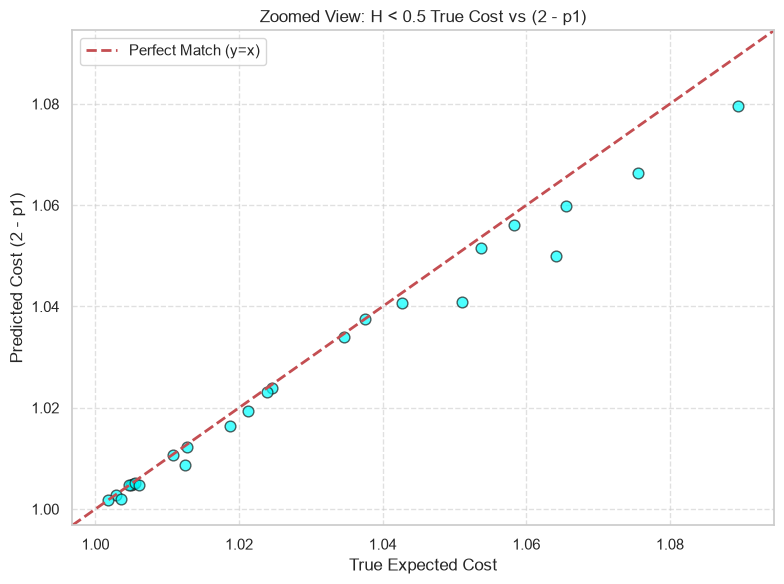

In [ ]:
import matplotlib.pyplot as plt

# Zoomed-in visualization for H < 0.5
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(df_low_h['true_expected_cost'], df_low_h['formula_2_minus_p1'], 
           alpha=0.7, edgecolors='k', color='cyan', s=60)

# Calculate dynamic limits based on the data's actual bounds
min_val = min(df_low_h['true_expected_cost'].min(), df_low_h['formula_2_minus_p1'].min()) - 0.005
max_val = max(df_low_h['true_expected_cost'].max(), df_low_h['formula_2_minus_p1'].max()) + 0.005

# Plot perfect match line within the new bounds
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label="Perfect Match (y=x)")

ax.set_xlim(min_val, max_val)
ax.set_ylim(min_val, max_val)

ax.set_title("Zoomed View: H < 0.5 True Cost vs (2 - p1)")
ax.set_xlabel("True Expected Cost")
ax.set_ylabel("Predicted Cost (2 - p1)")
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

=== BOUNDARY POINT AT H = 0.5 ===
p1 at H=0.5:     0.88997
Boundary Cost:   1.11003

=== CONSTRAINED LOG MODEL (H >= 0.5) ===
Formula: 1.1100 + 0.7049 * ln(1 + 0.9169 * (H - 0.5))
MAE:  0.07266
RMSE: 0.09060
R²:   0.90876



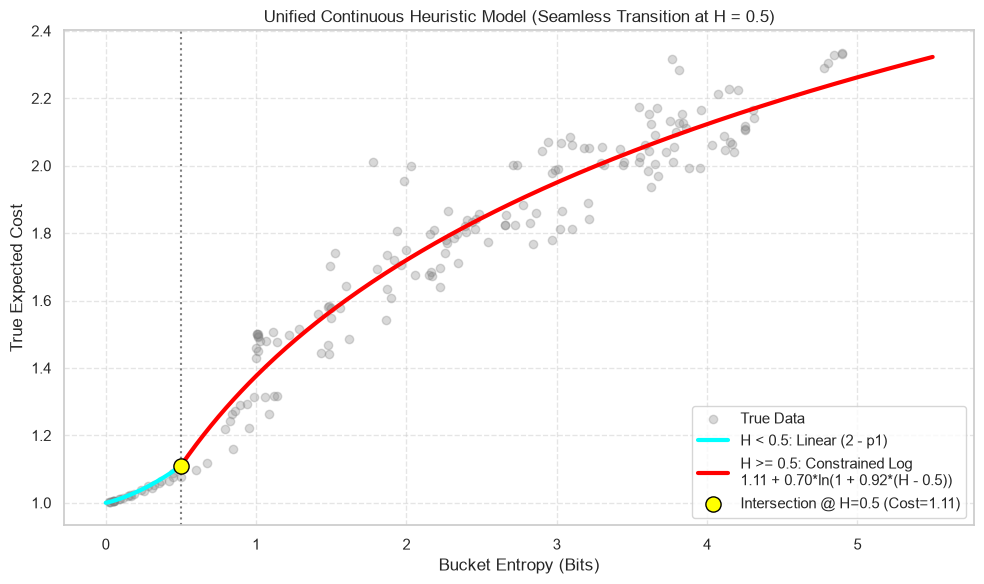

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, brentq
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ---------------------------------------------------------------------
# 1. Calculate Exact Boundary Point at H = 0.5
# ---------------------------------------------------------------------
def binary_entropy_diff(p):
    return (-p * np.log2(p) - (1 - p) * np.log2(1 - p)) - 0.5

# Find exact p1 for H = 0.5
p1_at_05 = brentq(binary_entropy_diff, 0.50001, 0.99999)
C_SPLIT = 2.0 - p1_at_05  # ~1.1100

print(f"=== BOUNDARY POINT AT H = 0.5 ===")
print(f"p1 at H=0.5:     {p1_at_05:.5f}")
print(f"Boundary Cost:   {C_SPLIT:.5f}\n")

# ---------------------------------------------------------------------
# 2. Define and Fit Constrained Logarithmic Model (H >= 0.5)
# ---------------------------------------------------------------------
def model_log_constrained(h, a, b):
    dh = np.maximum(0.0, h - 0.5)
    return C_SPLIT + a * np.log1p(b * dh)

df_high = df[df['bucket_entropy'] >= 0.5].copy()
X_high = df_high['bucket_entropy'].values
Y_high = df_high['true_expected_cost'].values

# Fit parameters a and b with initial guess [0.5, 1.0]
popt_constrained, _ = curve_fit(model_log_constrained, X_high, Y_high, p0=[0.5, 1.0], bounds=(0, np.inf))
a_fit, b_fit = popt_constrained

Y_pred_high = model_log_constrained(X_high, a_fit, b_fit)

mae_c = mean_absolute_error(Y_high, Y_pred_high)
rmse_c = np.sqrt(mean_squared_error(Y_high, Y_pred_high))
r2_c = r2_score(Y_high, Y_pred_high)

print(f"=== CONSTRAINED LOG MODEL (H >= 0.5) ===")
print(f"Formula: {C_SPLIT:.4f} + {a_fit:.4f} * ln(1 + {b_fit:.4f} * (H - 0.5))")
print(f"MAE:  {mae_c:.5f}")
print(f"RMSE: {rmse_c:.5f}")
print(f"R²:   {r2_c:.5f}\n")

# ---------------------------------------------------------------------
# 3. Unified Visualization Across Entire Domain
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

# Plot raw true data
ax.scatter(df['bucket_entropy'], df['true_expected_cost'], alpha=0.3, color='gray', label='True Data')

# Generate unified smooth curve across both regions
h_low = np.linspace(0.0, 0.5, 100)
# Approximate linear cost based on binary entropy inversion for low H
p1_low = np.array([brentq(lambda p: (-p*np.log2(p) - (1-p)*np.log2(1-p)) - h, 0.50001, 0.99999) if h > 1e-6 else 1.0 for h in h_low])
cost_low = 2.0 - p1_low

h_high = np.linspace(0.5, max(df['bucket_entropy'].max(), 5.5), 300)
cost_high = model_log_constrained(h_high, a_fit, b_fit)

# Plot Low H segment
ax.plot(h_low, cost_low, color='cyan', lw=3, label='H < 0.5: Linear (2 - p1)')

# Plot High H segment
ax.plot(h_high, cost_high, color='red', lw=3, label=f'H >= 0.5: Constrained Log\n{C_SPLIT:.2f} + {a_fit:.2f}*ln(1 + {b_fit:.2f}*(H - 0.5))')

# Highlight intersection point
ax.scatter([0.5], [C_SPLIT], color='yellow', s=120, zorder=5, edgecolors='black', label=f'Intersection @ H=0.5 (Cost={C_SPLIT:.2f})')
ax.axvline(0.5, color='black', linestyle=':', alpha=0.5)

ax.set_title("Unified Continuous Heuristic Model (Seamless Transition at H = 0.5)")
ax.set_xlabel("Bucket Entropy (Bits)")
ax.set_ylabel("True Expected Cost")
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()